# Laboratorio 6 — Análisis de datos de entrada y bondad de ajuste (*goodness of fit*)

**Universidad de los Llanos — Simulación Computacional**
Práctica: Análisis de datos de entrada y ajuste de datos a distribuciones de probabilidad (FO-DOC-112)

**Estudiante:** _________________________  **Fecha:** _____________

Contenido del notebook:

1. Consulta previa (Sección 2)
2. Configuración y carga de los datos
3. **5.1** Conjunto de datos: estadística descriptiva (Tabla 1) e histogramas (Figura 1)
4. **5.2** Análisis de datos de entrada: correlaciones de retraso, diagrama de dispersión, patrón de llegadas, conteo de llegadas por intervalos y media móvil
5. **5.3** Ajuste de curvas: 8 distribuciones evaluadas con SSE, AIC y BIC, tablas por conjunto, top‑3 y selección final
6. Conclusiones y bibliografía

## 2. Consulta previa

**¿En qué consiste la estadística descriptiva?**
Es la rama de la estadística que resume y describe un conjunto de datos sin hacer inferencias sobre la población. Usa medidas de **tendencia central** (media, mediana, moda), de **dispersión** (rango, varianza, desviación estándar, rango intercuartílico), de **posición** (percentiles, cuartiles) y de **forma** (asimetría, curtosis), además de representaciones gráficas (histogramas, diagramas de caja, gráficos de dispersión). En simulación es el primer paso del análisis de datos de entrada: permite intuir qué familias de distribuciones son candidatas antes de ajustar.

**¿Qué son la asimetría (*skewness*), la curtosis y los percentiles?**
- **Asimetría**: mide la falta de simetría de la distribución respecto a su media, $\gamma_1 = E[(X-\mu)^3]/\sigma^3$. Si $\gamma_1 = 0$ la distribución es simétrica (p. ej., normal); si $\gamma_1>0$ tiene cola larga a la derecha (exponencial $\gamma_1=2$, lognormal, gamma); si $\gamma_1<0$ la cola larga está a la izquierda.
- **Curtosis**: mide el peso de las colas / el apuntamiento, $\gamma_2 = E[(X-\mu)^4]/\sigma^4 - 3$ (exceso de curtosis). La normal tiene $\gamma_2 = 0$; $\gamma_2 > 0$ (leptocúrtica) indica colas pesadas y valores extremos frecuentes; $\gamma_2<0$ (platicúrtica) colas ligeras.
- **Percentiles**: el percentil $p$ es el valor por debajo del cual se encuentra el $p\%$ de las observaciones. Los cuartiles son $Q_1$ (25 %), $Q_2$ (50 %, la mediana) y $Q_3$ (75 %); $Q_3-Q_1$ es el rango intercuartílico, una medida de dispersión robusta a valores atípicos.

**¿Qué significa el supuesto de que un conjunto de variables aleatorias sea IID?**
IID = **independientes e idénticamente distribuidas**. *Independientes*: el valor de una observación no aporta información sobre las demás (en particular, $\mathrm{Cov}(X_i, X_{i+k}) = 0$ para todo retraso $k$). *Idénticamente distribuidas*: todas provienen de la misma distribución, con los mismos parámetros, sin importar en qué momento se observen. Este supuesto es el que justifica ajustar **una única** distribución univariada a la muestra y generar en la simulación valores independientes de ella.

**¿En qué consiste un proceso estocástico estacionario?**
Un proceso $\{X_t\}$ es **estrictamente estacionario** si la distribución conjunta de $(X_{t_1},\dots,X_{t_n})$ es igual a la de $(X_{t_1+h},\dots,X_{t_n+h})$ para cualquier desplazamiento $h$: sus propiedades probabilísticas no cambian con el tiempo. En la práctica se usa la estacionariedad **débil** (de segundo orden): media constante, varianza constante y covarianza entre $X_t$ y $X_{t+k}$ que depende solo del retraso $k$. Un proceso de llegadas cuya tasa cambia con la hora del día (p. ej., Poisson no homogéneo) **no** es estacionario.

**¿En qué consiste un proceso estocástico correlacionado?**
Es un proceso en el que las observaciones dependen de las anteriores: existe autocorrelación $\rho_k = \mathrm{Cov}(X_t, X_{t+k})/\sigma^2 \ne 0$ para algún retraso $k$. Por ejemplo, un proceso autorregresivo $X_t = \alpha X_{t-1} + (1-\alpha)U_t$: un valor alto tiende a ser seguido por otro valor alto. Ignorar la correlación y modelarlo como IID suele subestimar la variabilidad y distorsionar medidas como tiempos de espera en colas.

## Configuración y carga de datos

Los cuatro archivos (`dataset-A.txt` … `dataset-D.txt`) contienen **200 observaciones** cada uno, un valor por línea. Si se ejecuta en Google Colab y los archivos no están en el directorio de trabajo, la celda de carga abre el diálogo para subirlos.

In [1]:
%matplotlib inline
import os
import warnings
import numpy as np
import pandas as pd
import scipy.stats as st
import matplotlib.pyplot as plt
from statsmodels.graphics import tsaplots

warnings.filterwarnings('ignore')
pd.set_option('display.float_format', lambda v: f'{v:,.6g}')
plt.rcParams['figure.dpi'] = 100

In [2]:
NAMES = ['A', 'B', 'C', 'D']
FILES = {k: f'dataset-{k}.txt' for k in NAMES}

# En Colab: si los archivos no existen, se piden para subirlos
missing = [f for f in FILES.values() if not os.path.exists(f)]
if missing:
    try:
        from google.colab import files
        print('Suba los archivos:', missing)
        files.upload()
    except ImportError:
        raise FileNotFoundError(f'No se encontraron: {missing}')

data = {k: np.loadtxt(f) for k, f in FILES.items()}
for k, x in data.items():
    print(f'Dataset {k}: {len(x)} observaciones, primeros valores: {np.round(x[:5], 4)}')

Dataset A: 200 observaciones, primeros valores: [0.021  0.0814 0.1562 0.1494 0.1934]
Dataset B: 200 observaciones, primeros valores: [0.1521 0.0356 0.804  0.0073 0.0352]
Dataset C: 200 observaciones, primeros valores: [ 1.6159  0.9267  1.1669 16.6765 19.678 ]
Dataset D: 200 observaciones, primeros valores: [0.4637 0.2135 8.4562 8.1297 1.3658]


## 5.1 Conjunto de datos — Análisis preliminar con estadística descriptiva

### Tabla 1. Descripción estadística de los conjuntos de datos A, B, C y D

Se usa la varianza y desviación estándar **muestrales** (`ddof=1`).

In [3]:
def descriptiva(x):
    return {
        'Tamaño de la muestra': len(x),
        'Mínimo': np.min(x),
        'Máximo': np.max(x),
        'Media': np.mean(x),
        'Varianza': np.var(x, ddof=1),
        'Desviación estándar': np.std(x, ddof=1),
        'Percentil 25% (Q1)': np.percentile(x, 25),
        'Percentil 50% (Q2 o mediana)': np.percentile(x, 50),
        'Percentil 75% (Q3)': np.percentile(x, 75),
    }

tabla1 = pd.DataFrame({f'Dataset {k}': descriptiva(x) for k, x in data.items()})
tabla1.index.name = 'Medida estadística'
tabla1

,Dataset A,Dataset B,Dataset C,Dataset D
Medida estadística,,,,
Tamaño de la muestra,200,200,200,200
Mínimo,0.0209639,8.516e-05,0.926681,0.111505
Máximo,0.298966,1.55131,"6,669.85",17.967
Media,0.195039,0.205393,762.394,2.0605
Varianza,0.00191929,0.0524807,"852,170",5.41299
Desviación estándar,0.0438098,0.229087,923.13,2.32658
Percentil 25% (Q1),0.163843,0.0463288,152.912,0.634291
Percentil 50% (Q2 o mediana),0.192074,0.137676,455.558,1.40636
Percentil 75% (Q3),0.230109,0.290179,"1,028.59",2.52891


Medidas complementarias (no exigidas en la Tabla 1, pero útiles para el análisis de forma): coeficiente de variación $CV = s/\bar{x}$, asimetría y exceso de curtosis.

In [4]:
extra = pd.DataFrame({f'Dataset {k}': {
    'Coef. de variación (s/media)': np.std(x, ddof=1) / np.mean(x),
    'Asimetría (skewness)': st.skew(x),
    'Exceso de curtosis': st.kurtosis(x),
    'Rango intercuartílico (Q3-Q1)': np.percentile(x, 75) - np.percentile(x, 25),
} for k, x in data.items()})
extra

,Dataset A,Dataset B,Dataset C,Dataset D
Coef. de variación (s/media),0.224621,1.11536,1.21083,1.12914
Asimetría (skewness),-0.289519,2.40637,2.4821,3.1596
Exceso de curtosis,0.309005,7.97405,9.10089,14.0891
Rango intercuartílico (Q3-Q1),0.0662666,0.24385,875.679,1.89462


### Figura 1. Histogramas de distribuciones de los conjuntos de datos A, B, C y D (20 *bins*)

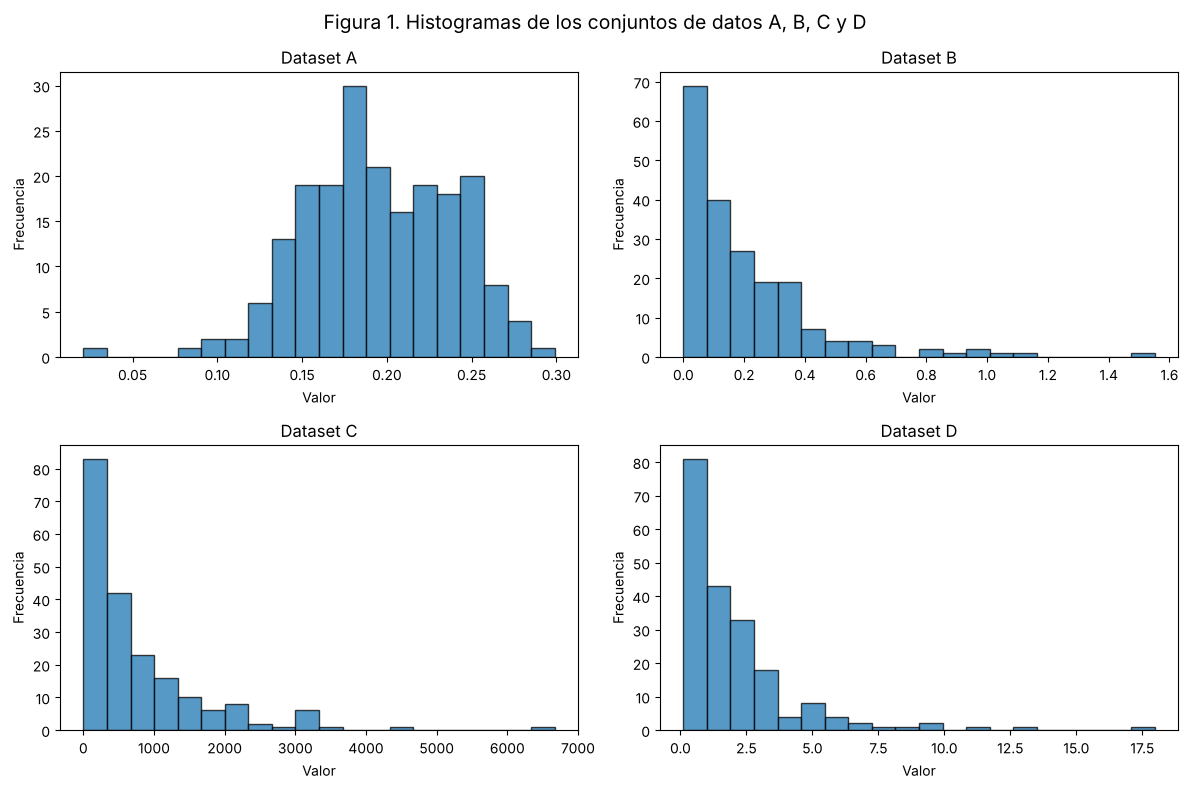

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (k, x) in zip(axes.ravel(), data.items()):
    ax.hist(x, bins=20, color='tab:blue', edgecolor='black', alpha=0.75)
    ax.set_title(f'Dataset {k}')
    ax.set_xlabel('Valor')
    ax.set_ylabel('Frecuencia')
fig.suptitle('Figura 1. Histogramas de los conjuntos de datos A, B, C y D', fontsize=14)
plt.tight_layout()
plt.show()

### ¿Qué puede analizar de las medidas de estadística descriptiva y los histogramas?

- **Dataset A** — Valores en un rango estrecho (≈0.02 a 0.30), media ≈ 0.195 y mediana ≈ 0.192 casi iguales, desviación pequeña (CV ≈ 0.22) y asimetría ligeramente negativa (≈ −0.29). El histograma es **unimodal y aproximadamente simétrico, con forma de campana**. Candidatas: normal, Weibull con forma alta, beta, gamma con forma grande. Una distribución exponencial queda descartada (exige CV = 1 y moda en cero).
- **Dataset B** — Mínimo prácticamente cero, media ≈ 0.205 muy cercana a la desviación estándar ≈ 0.229 (**CV ≈ 1.1**), mediana (≈0.14) bastante menor que la media y asimetría ≈ 2.4. El histograma es **decreciente desde cero con cola larga a la derecha**: es la firma típica de una **exponencial** (CV = 1, asimetría = 2) o de gamma/Weibull con parámetro de forma cercano a 1.
- **Dataset C** — Escala muy distinta (de ≈1 a ≈6670), media ≈ 762 frente a mediana ≈ 456, desviación (≈923) mayor que la media (CV ≈ 1.2) y asimetría ≈ 2.5 con curtosis alta. El histograma está **muy concentrado cerca de cero con una cola derecha muy larga**. Por sí solo sugiere exponencial / gamma / Weibull con forma < 1, pero como se verá en 5.2 los datos no son estacionarios.
- **Dataset D** — Media ≈ 2.06 > mediana ≈ 1.41, CV ≈ 1.1, asimetría ≈ 3.2 y exceso de curtosis ≈ 14 (valores extremos de hasta ≈18, unas 7.8 desviaciones por encima de la media). El histograma es **sesgado a la derecha con una cola muy pesada**; a diferencia de B, el mínimo (≈0.11) no está pegado a cero. Esto apunta a **lognormal** o log‑logística, aunque exponencial/gamma también son candidatas.

En resumen: A es simétrico y poco disperso; B, C y D son positivos y sesgados a la derecha, con colas cada vez más pesadas (D y C). La estadística descriptiva sola **no** basta para saber si los datos son IID; eso se evalúa en 5.2.

## 5.2 Análisis de datos de entrada

Siguiendo el notebook *Example. Input Data Analysis.ipynb*, cada conjunto se interpreta como una secuencia de **tiempos entre llegadas** $x_1, x_2, \dots, x_{200}$, de modo que los instantes de llegada son $t_i = \sum_{j\le i} x_j$ y el horizonte observado es $T = \sum x_i$.

Las funciones de graficación se adaptaron del notebook de clase para (i) dibujar los 4 conjuntos lado a lado y (ii) funcionar con horizontes $T$ no enteros (en el original `step = round(T/nbins)` puede valer 0 cuando $T$ es pequeño, como en A y B, y el conteo usaba `counts[k-1]`, lo que desplazaba el primer intervalo al final).

In [6]:
def plot_lag_correlations(ax, x, k, lags=20):
    tsaplots.plot_acf(x, lags=lags, zero=False, ax=ax, title=f'Dataset {k}')
    ax.set_xlabel('Retraso k (lag)')
    ax.set_ylabel('Correlación')
    ax.set_ylim(-1, 1)
    ax.set_xticks(np.arange(1, lags + 1, 1))
    ax.set_xlim(0.5, lags + 0.5)

def plot_scatter(ax, x, k):
    ax.scatter(x[:-1], x[1:], marker='^', s=18)
    ax.grid(alpha=0.4)
    ax.set_title(f'Dataset {k}')
    ax.set_xlabel('Observación [k]')
    ax.set_ylabel('Observación [k+1]')
    ax.set_xlim(x.min(), x.max())
    ax.set_ylim(x.min(), x.max())

def plot_arrival_time_pattern(ax, x, k):
    t = np.cumsum(x)
    prop = np.arange(1, len(x) + 1) / len(x)
    ax.plot(t, prop, 'b', label='Datos')
    ax.plot([0, t[-1]], [0, 1], 'k--', lw=1, label='Tasa constante')
    ax.set_title(f'Dataset {k}')
    ax.set_xlabel('Tiempo T')
    ax.set_ylabel('Proporción antes de T')
    ax.legend(loc='upper left', fontsize=8)

def plot_arrival_counts(ax, x, k, nbins=40):
    t = np.cumsum(x)
    T = t[-1]
    counts, edges = np.histogram(t, bins=nbins, range=(0, T))
    ax.bar(range(1, nbins + 1), counts, width=1, edgecolor='black', color='white')
    ax.axhline(len(x) / nbins, color='red', ls='--', lw=1, label='Conteo esperado si la tasa es constante')
    ax.set_title(f'Dataset {k}: {nbins} intervalos de ancho {T / nbins:.4g} entre 0 y {T:.4g}', fontsize=9)
    ax.set_xlabel('Intervalo')
    ax.set_ylabel('Conteo')
    ax.legend(fontsize=7)

def moving_average(x, window):
    half = window // 2
    return np.array([np.mean(x[max(0, i - half): min(len(x), i + half)]) for i in range(len(x))])

def plot_moving_average(ax, x, k, window=20):
    ma = moving_average(x, window)
    m, s = np.mean(ma), np.std(ma)
    ax.plot(ma, label='Media móvil')
    ax.axhline(m, color='black', lw=1, label='Media')
    ax.axhline(m + 3 * s, color='green', lw=1, label='±3σ')
    ax.axhline(m - 3 * s, color='green', lw=1)
    ax.set_ylim(m - 9 * s, m + 9 * s)
    ax.set_xlim(0, len(ma))
    ax.set_title(f'Dataset {k}: media móvil con W = {window}')
    ax.set_xlabel('Posición')
    ax.set_ylabel('Media móvil')
    ax.legend(fontsize=7)

def grid(plot_fn, title, **kw):
    fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
    for ax, (k, x) in zip(axes.ravel(), data.items()):
        plot_fn(ax, x, k, **kw)
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

Como referencia previa, la secuencia de los valores en el orden en que fueron observados:

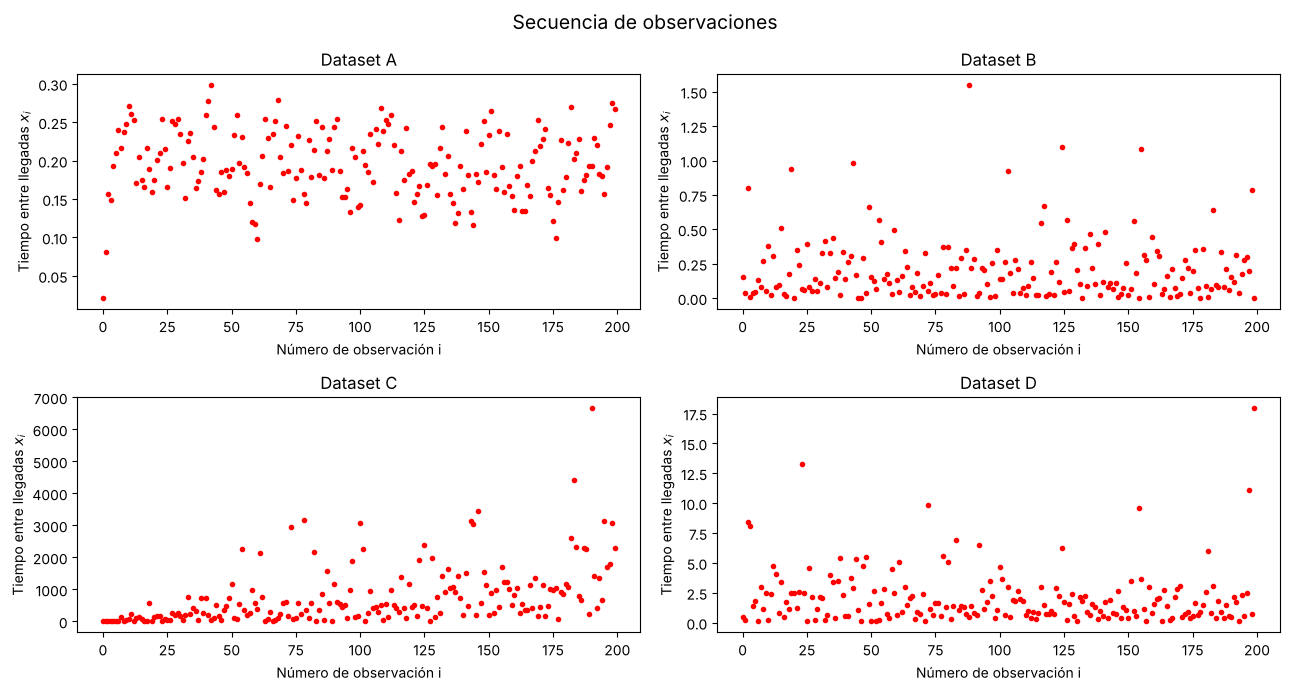

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, (k, x) in zip(axes.ravel(), data.items()):
    ax.plot(x, 'r.')
    ax.set_title(f'Dataset {k}')
    ax.set_xlabel('Número de observación i')
    ax.set_ylabel('Tiempo entre llegadas $x_i$')
fig.suptitle('Secuencia de observaciones', fontsize=14)
plt.tight_layout()
plt.show()

### a. Correlaciones de retraso estimadas (*Estimated lag correlations*)

Autocorrelación muestral $\hat\rho_k$ para $k = 1,\dots,20$. La banda sombreada es el intervalo de confianza del 95 % bajo la hipótesis de independencia (≈ $\pm 1.96/\sqrt{n} = \pm 0.139$).

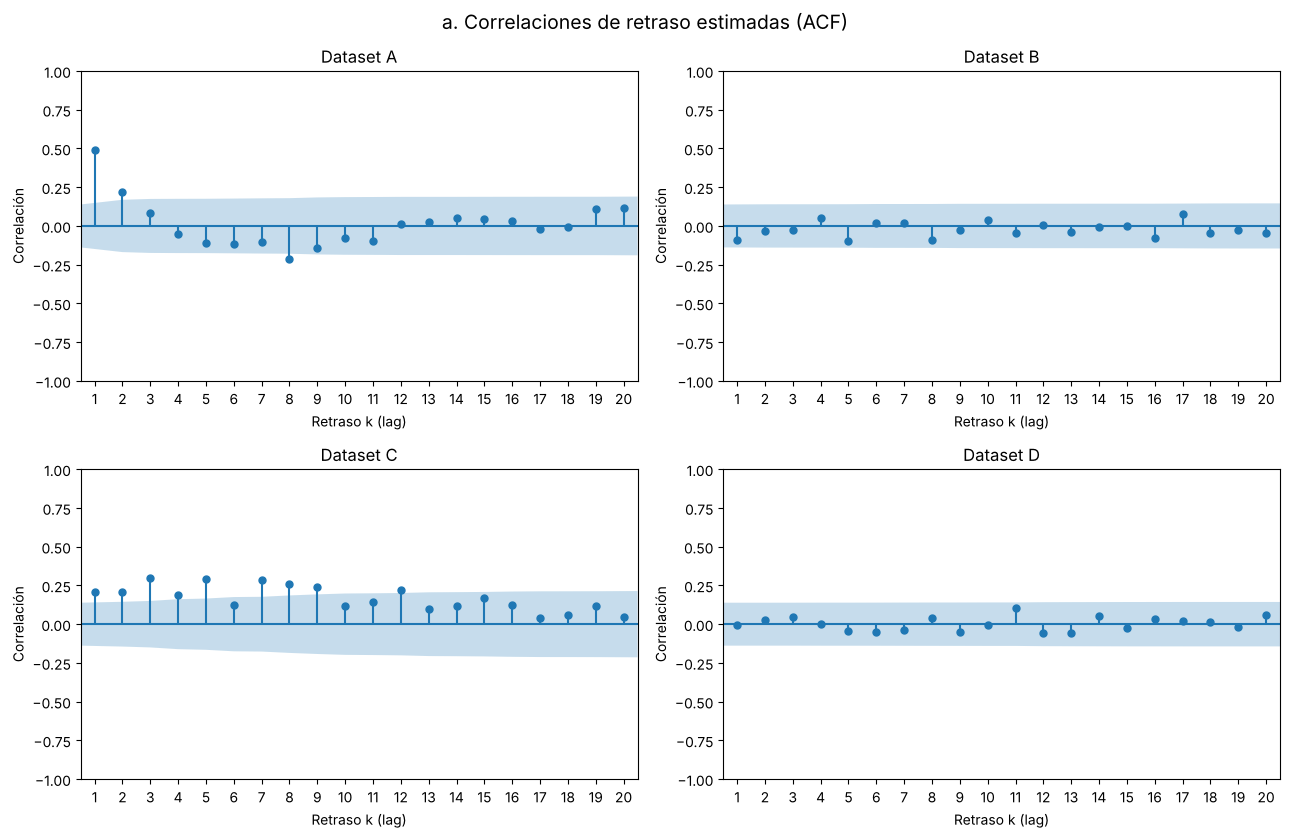

,Dataset A,Dataset B,Dataset C,Dataset D
rho_1,0.492202,-0.0923395,0.208361,-0.00238143
rho_2,0.220557,-0.0315445,0.207718,0.0298101
rho_3,0.085472,-0.0282011,0.300761,0.0435264
rho_4,-0.0529435,0.0507621,0.188838,0.0024653
rho_5,-0.109625,-0.0941536,0.291978,-0.0434547
Retrasos fuera de ±1.96/√n (k≤20),4,0,11,0
Ljung-Box p-valor (k=10),9.4473e-14,0.730964,3.53788e-19,0.987439


In [8]:
grid(plot_lag_correlations, 'a. Correlaciones de retraso estimadas (ACF)')

from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox
banda = 1.96 / np.sqrt(len(data['A']))
resumen_acf = pd.DataFrame({
    f'Dataset {k}': {
        **{f'rho_{l}': v for l, v in zip(range(1, 6), acf(x, nlags=5)[1:])},
        'Retrasos fuera de ±1.96/√n (k≤20)': int(np.sum(np.abs(acf(x, nlags=20)[1:]) > banda)),
        'Ljung-Box p-valor (k=10)': acorr_ljungbox(x, lags=[10])['lb_pvalue'].iloc[0],
    } for k, x in data.items()})
resumen_acf

### b. Diagrama de dispersión (*Scatter diagram*)

Cada punto es el par $(x_k, x_{k+1})$. Si los datos son independientes, la nube no muestra ninguna tendencia; una nube alargada sobre la diagonal indica correlación positiva.

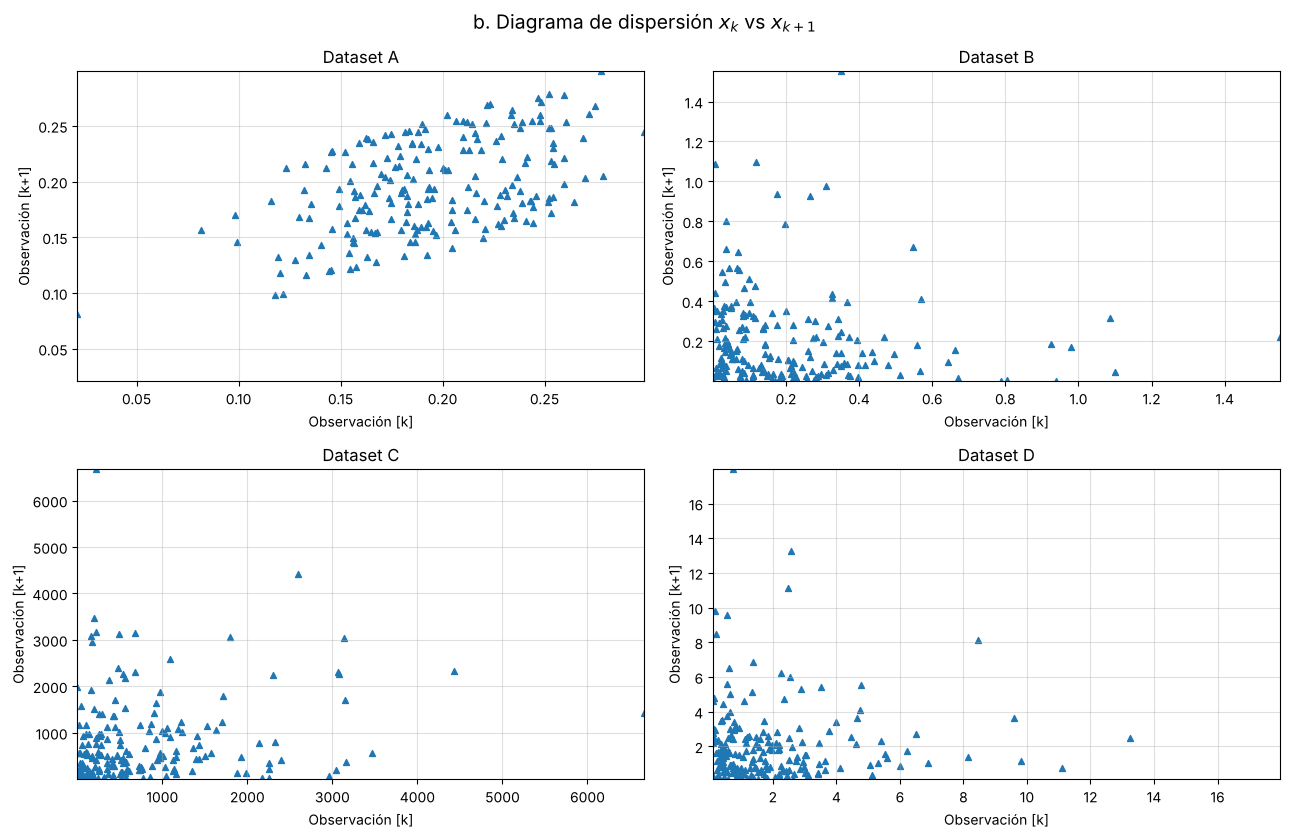

In [9]:
grid(plot_scatter, 'b. Diagrama de dispersión $x_k$ vs $x_{k+1}$')

### c. Patrón de hora de llegada (*Arrival time pattern*)

Proporción acumulada de llegadas antes del tiempo $T$. Para un proceso estacionario (tasa constante) la curva sigue la diagonal punteada.

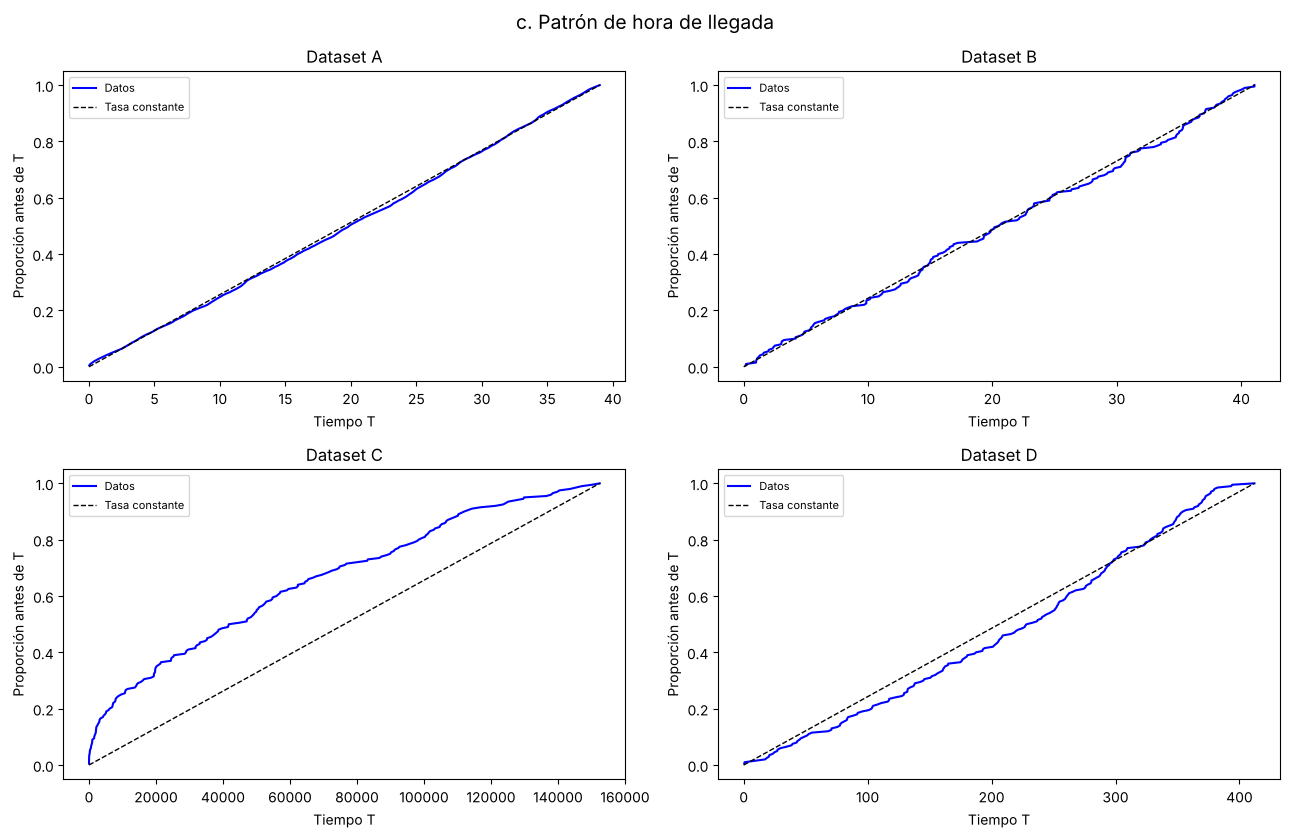

In [10]:
grid(plot_arrival_time_pattern, 'c. Patrón de hora de llegada')

### d. Conteo de llegadas vs intervalos (*Arrival counts vs intervals*)

El horizonte $[0, T]$ se divide en 40 intervalos de igual ancho y se cuentan las llegadas en cada uno. Con tasa constante los conteos fluctúan alrededor de $200/40 = 5$ (línea roja).

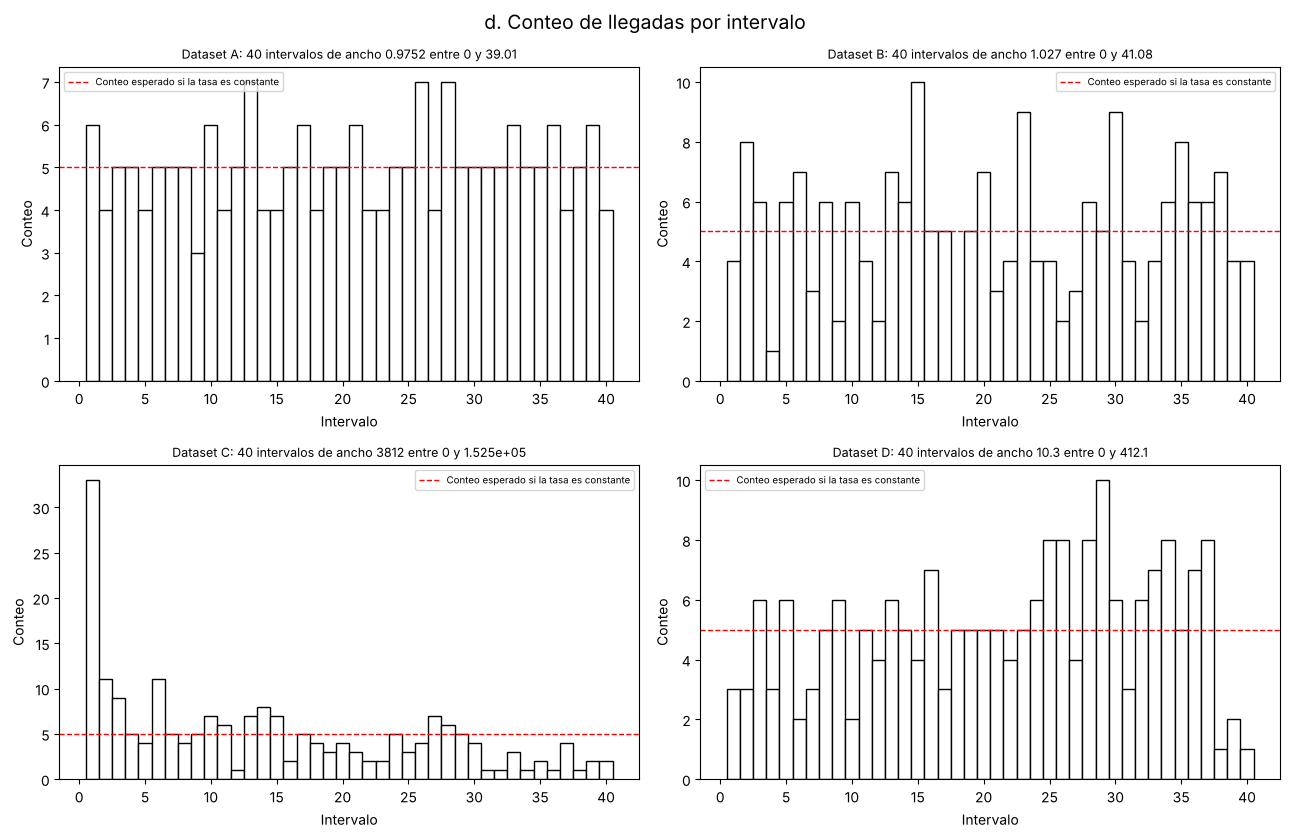

In [11]:
grid(plot_arrival_counts, 'd. Conteo de llegadas por intervalo', nbins=40)

### e. Gráfico de media móvil (*Moving average plot*)

Media móvil con ventana $W = 20$ (el notebook de clase usaba $W=100$ para ~1000 datos; aquí hay 200, así que se usa una ventana proporcional, un 10 % de la muestra). Una secuencia estable oscila alrededor de su media sin tendencia.

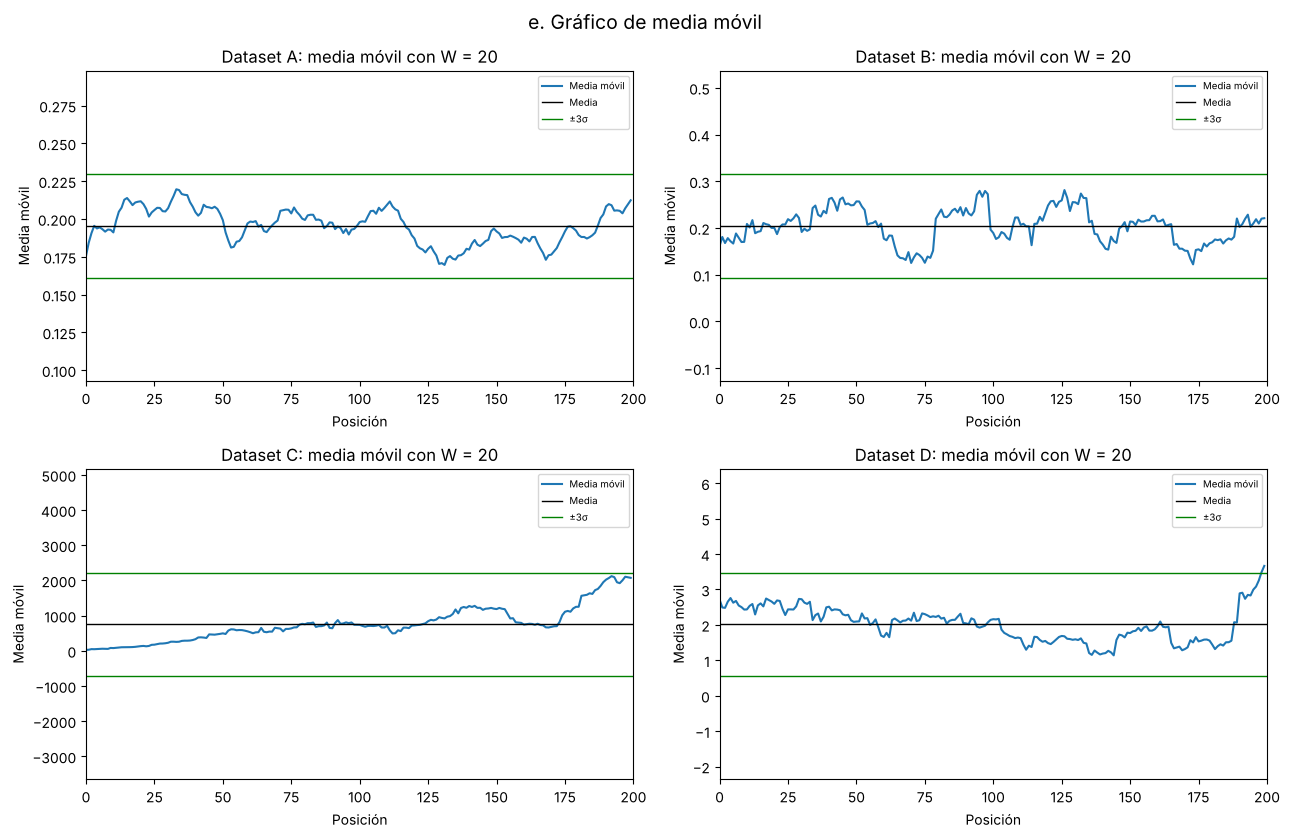

In [12]:
grid(plot_moving_average, 'e. Gráfico de media móvil', window=20)

Prueba complementaria de tendencia: correlación de Spearman entre la posición $i$ y el valor $x_i$, y comparación de la media de la primera y segunda mitad.

In [13]:
tend = pd.DataFrame({f'Dataset {k}': {
    'Spearman rho (i, x_i)': st.spearmanr(np.arange(len(x)), x)[0],
    'p-valor': st.spearmanr(np.arange(len(x)), x)[1],
    'Media 1a mitad': x[:100].mean(),
    'Media 2a mitad': x[100:].mean(),
} for k, x in data.items()})
tend

,Dataset A,Dataset B,Dataset C,Dataset D
"Spearman rho (i, x_i)",-0.104797,-0.00348009,0.603377,-0.117102
p-valor,0.13972,0.960993,3.21167e-21,0.0986615
Media 1a mitad,0.19876,0.204951,417.558,2.28299
Media 2a mitad,0.191317,0.205836,"1,107.23",1.83801


### ¿Qué se puede determinar de cada conjunto respecto a independencia / correlación y estabilidad?

**Dataset A — correlacionado, pero estable.**
La ACF muestra $\hat\rho_1 \approx 0.49$ y $\hat\rho_2 \approx 0.22$, claramente fuera de la banda de confianza, y decae rápidamente con el retraso (comportamiento típico de un proceso autorregresivo de orden 1, como el *Set 6* del ejemplo de clase). El diagrama de dispersión tiene una nube alargada sobre la diagonal: un valor alto suele ir seguido de otro alto. La prueba de Ljung‑Box rechaza la independencia (p ≈ 0). En cambio, el patrón de llegadas sigue la diagonal, los conteos por intervalo fluctúan alrededor de 5 y la media móvil se mantiene dentro de las bandas, así que el proceso **es estacionario pero no independiente**. → **No cumple el supuesto IID**; ajustar una distribución univariada describe bien la distribución marginal, pero para simular fielmente habría que modelar la dependencia (p. ej., un modelo AR(1)).

**Dataset B — consistente con IID.**
Todas las autocorrelaciones están dentro de la banda (Ljung‑Box no rechaza la independencia), la dispersión $x_k$ vs $x_{k+1}$ no muestra estructura (los puntos se concentran cerca del origen por la asimetría de los datos, como en el *Set 1* exponencial). El patrón de llegadas se mantiene sobre la diagonal, los conteos por intervalo varían aleatoriamente alrededor de 5 y la media móvil no tiene tendencia. → **Independiente y estacionario**: se puede modelar con una única distribución.

**Dataset C — no estacionario (tendencia creciente).**
La secuencia de valores y la media móvil **crecen claramente con el tiempo** (media de la segunda mitad ≈1107 frente a ≈418 en la primera, unas 2.7 veces; Spearman entre posición y valor ρ ≈ 0.60, p ≈ 10⁻²¹). El patrón de llegadas se separa de la diagonal: muchas llegadas al principio y cada vez menos al final, y los conteos por intervalo son muy altos al inicio (33 llegadas en el primer intervalo frente a 5 esperadas) y bajan a 1–2 en los últimos — la tasa de llegadas **disminuye** con el tiempo (los tiempos entre llegadas aumentan). La ACF muestra correlaciones positivas que **no decaen** con el retraso (≈0.2–0.3 en muchos retrasos), lo que es la huella de una tendencia, no de dependencia de corto plazo. → **No cumple IID** (análogo a los *Sets 4 y 5*, Poisson no homogéneo). Una sola distribución ajustada a todo el conjunto mezcla regímenes distintos; lo apropiado sería modelar la tasa como función del tiempo o ajustar por tramos.

**Dataset D — consistente con IID (con una leve variación no significativa).**
Las autocorrelaciones son prácticamente nulas (Ljung‑Box p ≈ 0.99) y la dispersión no muestra patrón. El patrón de llegadas sigue la diagonal de cerca. En los conteos por intervalo y en la media móvil se aprecia una leve disminución de los valores en la segunda mitad (media ≈1.84 frente a ≈2.28), pero la media móvil permanece dentro de las bandas de ±3σ (salvo al final, por el valor extremo de ≈18 en la última observación) y la prueba de tendencia no es significativa (Spearman p ≈ 0.10). → Se puede considerar **independiente y estacionario** y modelar con una única distribución (similar al *Set 3* lognormal del ejemplo); si se tuvieran más datos convendría confirmar que esa leve variación es solo aleatoria.

## 5.3 Ajuste de curvas y bondad de ajuste

Siguiendo a [Amat2021] y a los notebooks de clase, se ajustan por **máxima verosimilitud** (`scipy.stats.<dist>.fit`) las 5 distribuciones obligatorias y 4 adicionales:

| # | Distribución | `scipy.stats` | Justificación |
|---|---|---|---|
| a | Exponencial | `expon` | obligatoria |
| b | Lognormal | `lognorm` | obligatoria |
| c | Normal | `norm` | obligatoria |
| d | Gamma | `gamma` | obligatoria |
| e | Beta | `beta` | obligatoria |
| 1 | Weibull | `weibull_min` | generaliza la exponencial; muy usada para tiempos de servicio/vida |
| 2 | Log‑logística | `fisk` | similar a la lognormal con cola algo más pesada |
| 3 | Rayleigh | `rayleigh` | caso particular de Weibull (forma = 2), tiempos positivos |
| 4 | Gumbel (valor extremo, derecha) | `gumbel_r` | sesgada a la derecha, soporte en todos los reales |

**Decisiones de ajuste**

- Todos los datos son **positivos** (tiempos entre llegadas), así que para las distribuciones de soporte $[0,\infty)$ se fija `loc = 0` (`floc=0`). Con `loc` libre, el optimizador de SciPy produjo ajustes degenerados en varios casos (p. ej., gamma en C con forma 0.008, o AIC infinito en Weibull para B y D porque `loc` quedaba por encima del mínimo de los datos).
- La **beta** tiene soporte acotado $[0,1]$; como los datos no están en ese rango, se usa la beta de 4 parámetros con `loc = 0` y `scale` fijado en $1.01 \cdot \max(x)$, de modo que todos los datos queden dentro del soporte, y se estiman solo los dos parámetros de forma $(a, b)$.
- La normal y la Gumbel se ajustan con sus dos parámetros libres (`loc`, `scale`).

**Métricas de bondad de ajuste** (siendo $k$ el número de parámetros **estimados** —los fijados no cuentan— y $n = 200$):

- **SSE** (suma de errores cuadráticos) entre la densidad empírica del histograma y la PDF ajustada evaluada en el centro de cada clase: $SSE = \sum_j \big(\hat f_j - f(c_j;\hat\theta)\big)^2$. Se usan 20 clases, igual que en la Figura 1. Nota: el SSE depende de la escala de los datos, así que solo es comparable **dentro** de un mismo conjunto.
- **AIC** $= 2k - 2\ln\hat L$
- **BIC** $= k\ln n - 2\ln\hat L$

donde $\ln \hat L = \sum_i \ln f(x_i;\hat\theta)$ es la log‑verosimilitud. En las tres métricas, **menor es mejor**. Se añade además, como referencia, el p‑valor de la prueba de Kolmogórov‑Smirnov (orientativo, pues los parámetros se estimaron con los mismos datos).

In [14]:
DISTRIBUCIONES = {
    'Exponencial':   ('expon',       lambda x: dict(floc=0)),
    'Lognormal':     ('lognorm',     lambda x: dict(floc=0)),
    'Normal':        ('norm',        lambda x: dict()),
    'Gamma':         ('gamma',       lambda x: dict(floc=0)),
    'Beta':          ('beta',        lambda x: dict(floc=0, fscale=1.01 * np.max(x))),
    'Weibull':       ('weibull_min', lambda x: dict(floc=0)),
    'Log-logística': ('fisk',        lambda x: dict(floc=0)),
    'Rayleigh':      ('rayleigh',    lambda x: dict(floc=0)),
    'Gumbel':        ('gumbel_r',    lambda x: dict()),
}

def nombres_parametros(dist):
    shapes = dist.shapes.split(', ') if dist.shapes else []
    return shapes + ['loc', 'scale']

def ajustar(x, bins=20):
    n = len(x)
    dens, edges = np.histogram(x, bins=bins, density=True)
    centros = (edges[:-1] + edges[1:]) / 2
    filas, modelos = [], {}
    for nombre, (dname, fixed) in DISTRIBUCIONES.items():
        dist = getattr(st, dname)
        kw = fixed(x)
        params = dist.fit(x, **kw)
        k = len(params) - len(kw)                      # parámetros libres
        loglik = np.sum(dist.logpdf(x, *params))
        sse = np.sum((dens - dist.pdf(centros, *params)) ** 2)
        aic = 2 * k - 2 * loglik
        bic = k * np.log(n) - 2 * loglik
        ks_p = st.kstest(x, lambda v: dist.cdf(v, *params)).pvalue
        par_txt = ', '.join(f'{p}={v:.4g}' + ('*' if f'f{p}' in kw else '')
                            for p, v in zip(nombres_parametros(dist), params))
        filas.append({'Distribución de probabilidad': nombre, 'Parámetros': par_txt,
                      'k': k, 'SSE': sse, 'AIC': aic, 'BIC': bic, 'KS p-valor': ks_p})
        modelos[nombre] = (dist, params)
    tabla = pd.DataFrame(filas).set_index('Distribución de probabilidad')
    # ranking combinado: promedio de las posiciones en SSE, AIC y BIC
    tabla['Rank SSE'] = tabla['SSE'].rank().astype(int)
    tabla['Rank AIC'] = tabla['AIC'].rank().astype(int)
    tabla['Rank BIC'] = tabla['BIC'].rank().astype(int)
    tabla['Rank promedio'] = tabla[['Rank SSE', 'Rank AIC', 'Rank BIC']].mean(axis=1)
    return tabla, modelos

resultados = {k: ajustar(x) for k, x in data.items()}

def mostrar(k, num):
    tabla, _ = resultados[k]
    cols = ['Parámetros', 'SSE', 'AIC', 'BIC', 'KS p-valor', 'Rank promedio']
    print(f'Tabla {num}. Bondad de ajuste para el conjunto de datos {k}   (* = parámetro fijado, no estimado)')
    return (tabla[cols].style
            .format({'SSE': '{:.4g}', 'AIC': '{:.2f}', 'BIC': '{:.2f}', 'KS p-valor': '{:.3g}', 'Rank promedio': '{:.2f}'})
            .highlight_min(subset=['SSE', 'AIC', 'BIC'], color='#b6e3b6')
            .set_properties(subset=['Parámetros'], **{'text-align': 'left'}))

### Gráfica de las 8+1 distribuciones ajustadas sobre cada conjunto

Vista general antes de las tablas (la línea más gruesa en cada panel es la de menor AIC).

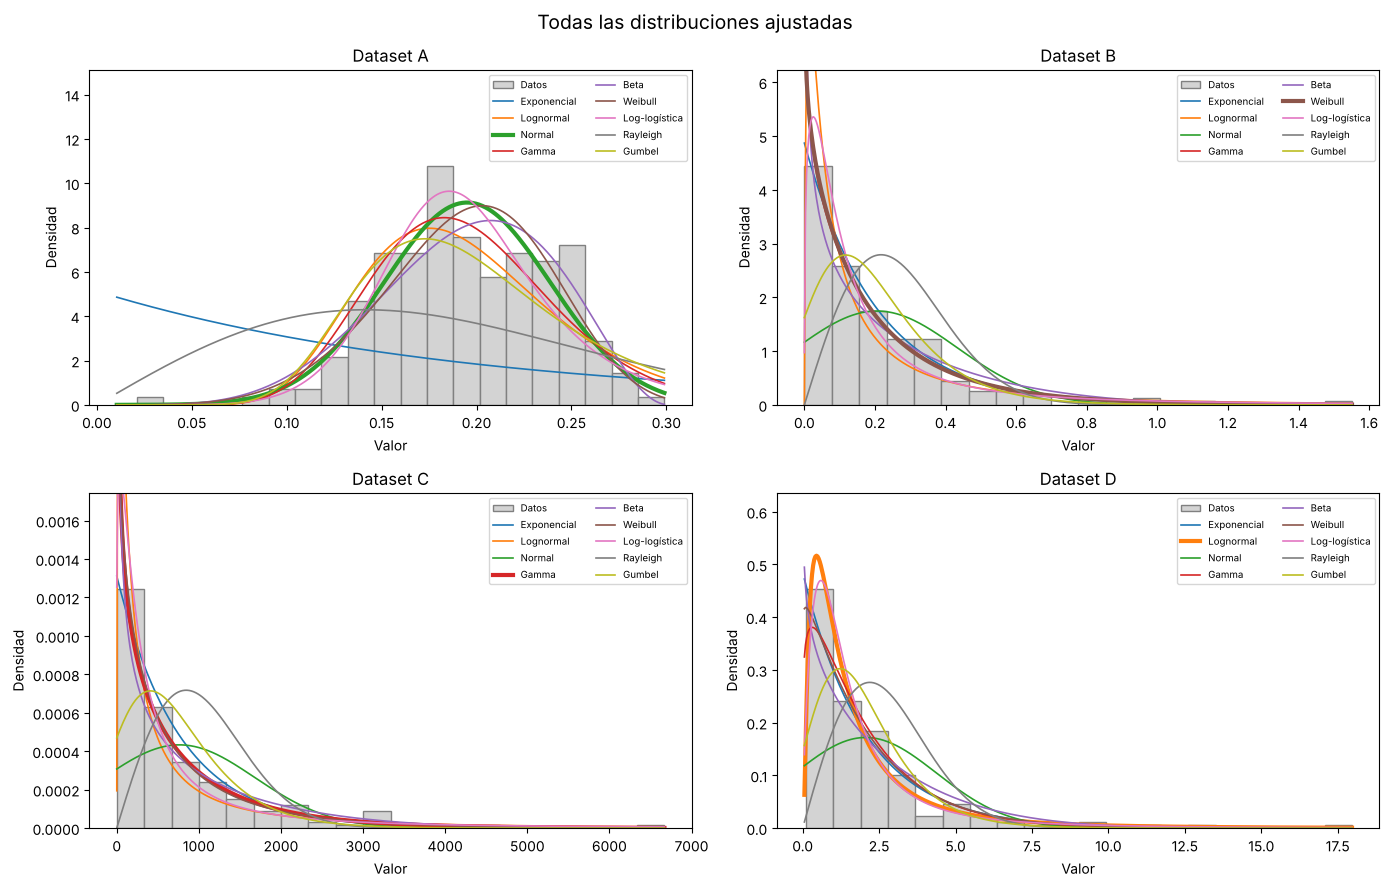

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (k, x) in zip(axes.ravel(), data.items()):
    tabla, modelos = resultados[k]
    mejor = tabla['AIC'].idxmin()
    ax.hist(x, bins=20, density=True, color='lightgray', edgecolor='gray', label='Datos')
    xs = np.linspace(max(1e-9, x.min() * 0.5), x.max(), 500)
    for nombre, (dist, params) in modelos.items():
        ax.plot(xs, dist.pdf(xs, *params), lw=3 if nombre == mejor else 1.2, label=nombre)
    ax.set_ylim(0, np.histogram(x, bins=20, density=True)[0].max() * 1.4)
    ax.set_title(f'Dataset {k}')
    ax.set_xlabel('Valor'); ax.set_ylabel('Densidad')
    ax.legend(fontsize=7, ncol=2)
fig.suptitle('Todas las distribuciones ajustadas', fontsize=14)
plt.tight_layout(); plt.show()

### Conjunto de datos A

#### Tabla 2. Bondad de ajuste para el conjunto de datos A

In [16]:
mostrar('A', 2)

Tabla 2. Bondad de ajuste para el conjunto de datos A   (* = parámetro fijado, no estimado)


,Parámetros,SSE,AIC,BIC,KS p-valor,Rank promedio
Distribución de probabilidad,,,,,,
Exponencial,"loc=0*, scale=0.195",340.5,-251.82,-248.52,1.71e-34,9.00
Lognormal,"s=0.275, loc=0*, scale=0.189",36.97,-611.09,-604.49,0.143,6.67
Normal,"loc=0.195, scale=0.0437",29.15,-680.59,-673.99,0.626,1.33
Gamma,"a=16.18, loc=0*, scale=0.01206",28.24,-647.34,-640.75,0.537,3.67
Beta,"a=5.902, b=3.234, loc=0*, scale=0.302*",29.36,-675.74,-669.14,0.195,3.00
Weibull,"c=5.071, loc=0*, scale=0.212",32.43,-679.36,-672.76,0.292,2.67
Log-logística,"c=7.293, loc=0*, scale=0.1927",33.42,-655.44,-648.85,0.479,4.33
Rayleigh,"loc=0*, scale=0.1413",185.2,-497.00,-493.70,3.28e-17,8.00
Gumbel,"loc=0.1728, scale=0.0491",42.53,-620.45,-613.85,0.0149,6.33


### Conjunto de datos B

#### Tabla 3. Bondad de ajuste para el conjunto de datos B

In [17]:
mostrar('B', 3)

Tabla 3. Bondad de ajuste para el conjunto de datos B   (* = parámetro fijado, no estimado)


,Parámetros,SSE,AIC,BIC,KS p-valor,Rank promedio
Distribución de probabilidad,,,,,,
Exponencial,"loc=0*, scale=0.2054",0.4358,-231.13,-227.83,0.336,2.33
Lognormal,"s=1.437, loc=0*, scale=0.104",2.326,-188.73,-182.14,0.137,6.00
Normal,"loc=0.2054, scale=0.2285",11.57,-18.89,-12.29,1.98e-06,8.00
Gamma,"a=0.8636, loc=0*, scale=0.2378",0.3158,-232.10,-225.50,0.949,2.33
Beta,"a=0.6894, b=4.115, loc=0*, scale=1.567*",1.111,-207.31,-200.71,0.138,4.00
Weibull,"c=0.9095, loc=0*, scale=0.1963",0.2762,-232.26,-225.67,0.96,1.33
Log-logística,"c=1.307, loc=0*, scale=0.1184",1.143,-206.65,-200.06,0.469,5.00
Rayleigh,"loc=0*, scale=0.2173",18.12,85.99,89.29,1.24e-21,9.00
Gumbel,"loc=0.1171, scale=0.132",5.729,-138.45,-131.85,0.00697,7.00


### Conjunto de datos C

#### Tabla 4. Bondad de ajuste para el conjunto de datos C

In [18]:
mostrar('C', 4)

Tabla 4. Bondad de ajuste para el conjunto de datos C   (* = parámetro fijado, no estimado)


,Parámetros,SSE,AIC,BIC,KS p-valor,Rank promedio
Distribución de probabilidad,,,,,,
Exponencial,"loc=0*, scale=762.4",5.978e-08,3056.59,3059.88,0.0667,3.33
Lognormal,"s=1.648, loc=0*, scale=324.3",6.361e-08,3084.19,3090.78,0.0222,5.67
Normal,"loc=762.4, scale=920.8",9.265e-07,3301.68,3308.28,8.75e-08,8.00
Gamma,"a=0.7062, loc=0*, scale=1080",4.493e-08,3040.22,3046.82,0.913,1.67
Beta,"a=0.5847, b=4.109, loc=0*, scale=6737*",1.298e-07,3061.97,3068.57,0.19,4.67
Weibull,"c=0.8007, loc=0*, scale=676",2.524e-08,3040.81,3047.41,0.941,1.67
Log-logística,"c=1.126, loc=0*, scale=384.4",4.076e-08,3072.48,3079.08,0.263,4.00
Rayleigh,"loc=0*, scale=845.3",1.434e-06,3481.09,3484.39,6.72e-30,9.00
Gumbel,"loc=409.7, scale=515.2",4.557e-07,3175.64,3182.24,0.00322,7.00


### Conjunto de datos D

#### Tabla 5. Bondad de ajuste para el conjunto de datos D

In [19]:
mostrar('D', 5)

Tabla 5. Bondad de ajuste para el conjunto de datos D   (* = parámetro fijado, no estimado)


,Parámetros,SSE,AIC,BIC,KS p-valor,Rank promedio
Distribución de probabilidad,,,,,,
Exponencial,"loc=0*, scale=2.06",0.009898,691.18,694.48,0.372,3.33
Lognormal,"s=1.019, loc=0*, scale=1.273",0.006913,675.89,682.49,0.591,1.33
Normal,"loc=2.06, scale=2.321",0.1175,908.33,914.93,1.59e-07,8.00
Gamma,"a=1.178, loc=0*, scale=1.749",0.01048,689.97,696.56,0.427,3.67
Beta,"a=0.8645, b=5.872, loc=0*, scale=18.15*",0.0249,739.02,745.62,0.00403,6.00
Weibull,"c=1.042, loc=0*, scale=2.099",0.01066,692.55,699.14,0.352,5.00
Log-logística,"c=1.705, loc=0*, scale=1.31",0.006011,681.40,688.00,0.661,1.67
Rayleigh,"loc=0*, scale=2.194",0.1572,934.06,937.36,1.09e-18,9.00
Gumbel,"loc=1.228, scale=1.216",0.0487,756.07,762.67,0.0177,7.00


### Las tres mejores distribuciones por conjunto de datos

Se ordenan las distribuciones por el **rango promedio** en SSE, AIC y BIC (cada métrica asigna una posición 1–9; se promedian). Así se combinan el ajuste a la forma del histograma (SSE) y el ajuste por verosimilitud penalizado por complejidad (AIC/BIC). En caso de empate, se desempata por BIC.

In [20]:
top3 = {}
for k in NAMES:
    tabla, _ = resultados[k]
    top3[k] = tabla.sort_values(['Rank promedio', 'BIC']).head(3)
    print(f'===== Dataset {k}: top 3 =====')
    display(top3[k][['Parámetros', 'SSE', 'AIC', 'BIC', 'Rank promedio']])

===== Dataset A: top 3 =====


,Parámetros,SSE,AIC,BIC,Rank promedio
Distribución de probabilidad,,,,,
Normal,"loc=0.195, scale=0.0437",29.1478,-680.587,-673.99,1.33333
Weibull,"c=5.071, loc=0*, scale=0.212",32.4271,-679.356,-672.76,2.66667
Beta,"a=5.902, b=3.234, loc=0*, scale=0.302*",29.3584,-675.736,-669.14,3


===== Dataset B: top 3 =====


,Parámetros,SSE,AIC,BIC,Rank promedio
Distribución de probabilidad,,,,,
Weibull,"c=0.9095, loc=0*, scale=0.1963",0.276188,-232.264,-225.667,1.33333
Exponencial,"loc=0*, scale=0.2054",0.435755,-231.131,-227.833,2.33333
Gamma,"a=0.8636, loc=0*, scale=0.2378",0.315773,-232.098,-225.501,2.33333


===== Dataset C: top 3 =====


,Parámetros,SSE,AIC,BIC,Rank promedio
Distribución de probabilidad,,,,,
Gamma,"a=0.7062, loc=0*, scale=1080",4.49321e-08,"3,040.22","3,046.82",1.66667
Weibull,"c=0.8007, loc=0*, scale=676",2.5238e-08,"3,040.81","3,047.41",1.66667
Exponencial,"loc=0*, scale=762.4",5.97832e-08,"3,056.59","3,059.88",3.33333


===== Dataset D: top 3 =====


,Parámetros,SSE,AIC,BIC,Rank promedio
Distribución de probabilidad,,,,,
Lognormal,"s=1.019, loc=0*, scale=1.273",0.00691347,675.893,682.489,1.33333
Log-logística,"c=1.705, loc=0*, scale=1.31",0.00601113,681.403,687.999,1.66667
Exponencial,"loc=0*, scale=2.06",0.00989812,691.179,694.477,3.33333


### Histograma de cada conjunto con las 3 distribuciones de mejor ajuste

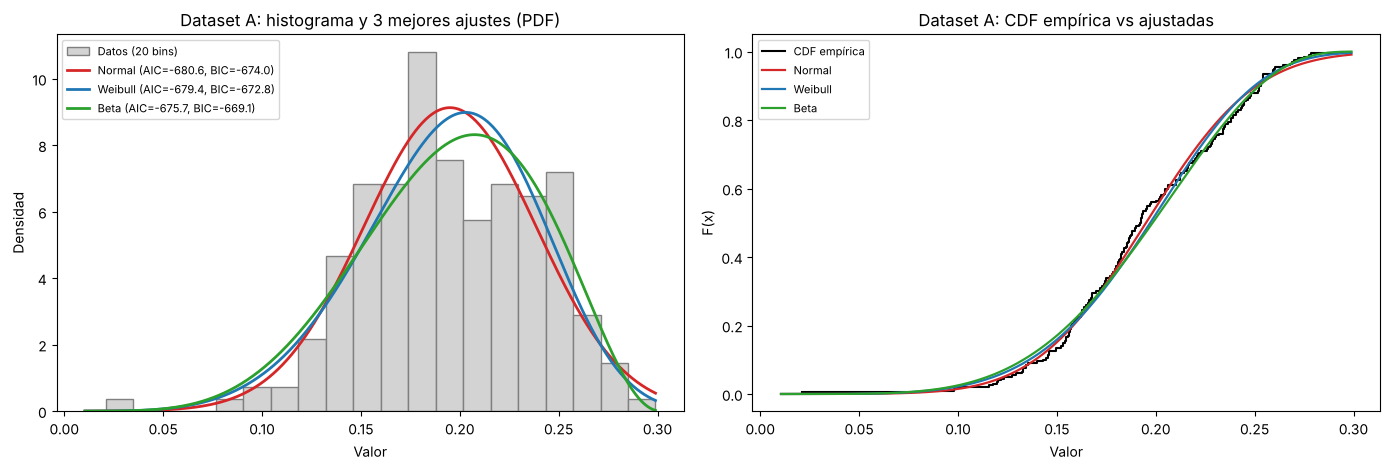

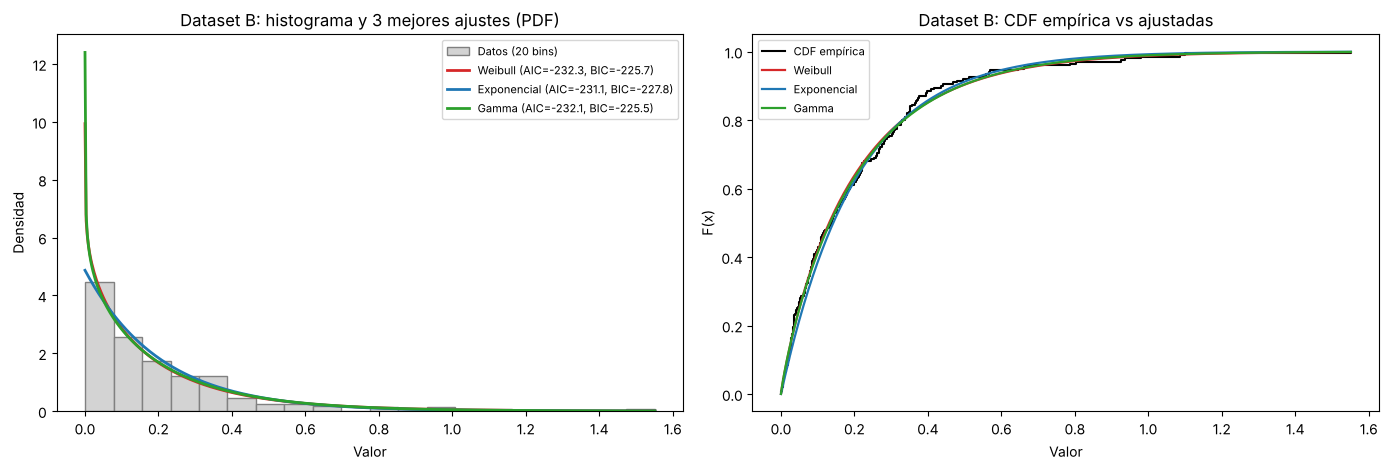

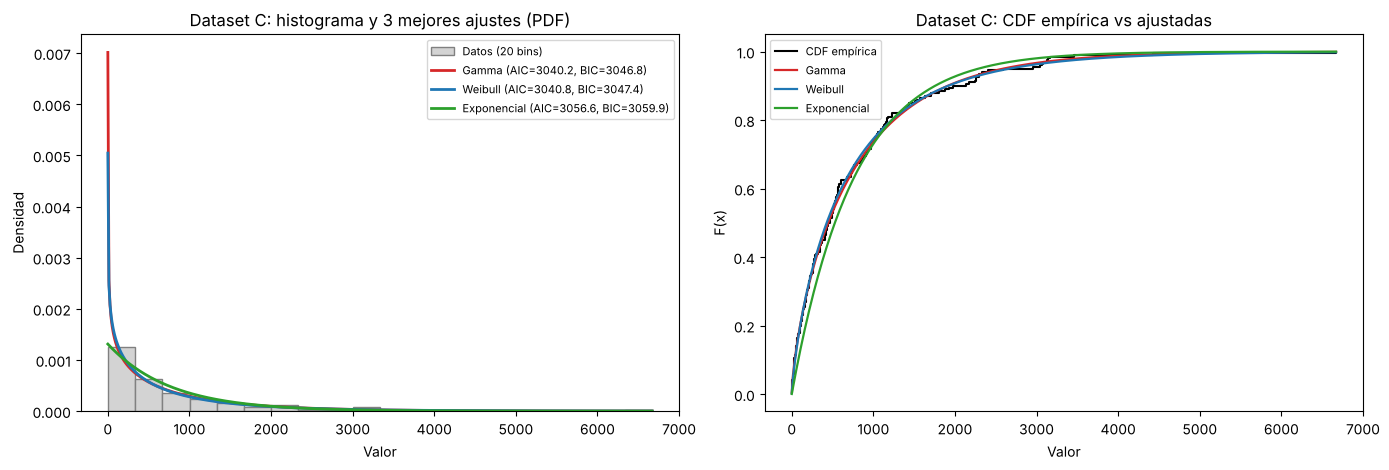

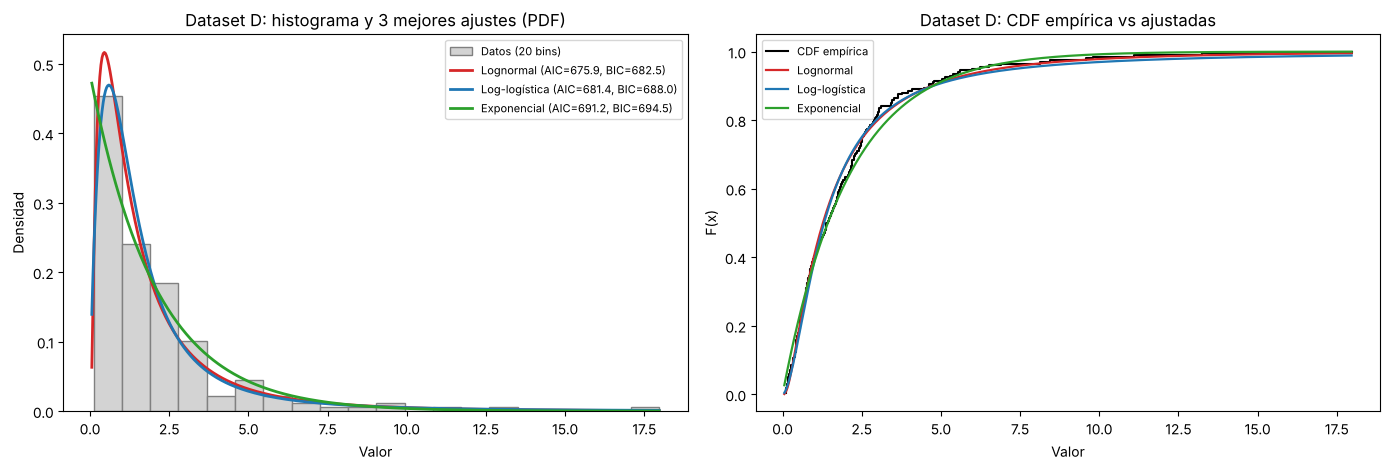

In [21]:
colores = ['tab:red', 'tab:blue', 'tab:green']
for k in NAMES:
    x = data[k]
    _, modelos = resultados[k]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
    ax1.hist(x, bins=20, density=True, color='lightgray', edgecolor='gray', label='Datos (20 bins)')
    xs = np.linspace(max(1e-9, x.min() * 0.5), x.max(), 500)
    for c, (nombre, fila) in zip(colores, top3[k].iterrows()):
        dist, params = modelos[nombre]
        ax1.plot(xs, dist.pdf(xs, *params), color=c, lw=2,
                 label=f"{nombre} (AIC={fila['AIC']:.1f}, BIC={fila['BIC']:.1f})")
    ax1.set_title(f'Dataset {k}: histograma y 3 mejores ajustes (PDF)')
    ax1.set_xlabel('Valor'); ax1.set_ylabel('Densidad'); ax1.legend(fontsize=8)

    # CDF empírica vs ajustadas: muestra mejor las diferencias en las colas
    xsort = np.sort(x)
    ax2.step(xsort, np.arange(1, len(x) + 1) / len(x), where='post', color='black', label='CDF empírica')
    for c, nombre in zip(colores, top3[k].index):
        dist, params = modelos[nombre]
        ax2.plot(xs, dist.cdf(xs, *params), color=c, lw=1.6, label=nombre)
    ax2.set_title(f'Dataset {k}: CDF empírica vs ajustadas')
    ax2.set_xlabel('Valor'); ax2.set_ylabel('F(x)'); ax2.legend(fontsize=8)
    plt.tight_layout(); plt.show()

Gráficos Q‑Q de las tres mejores distribuciones (si el ajuste es bueno, los puntos caen sobre la diagonal; aquí se ven con claridad los problemas en las colas).

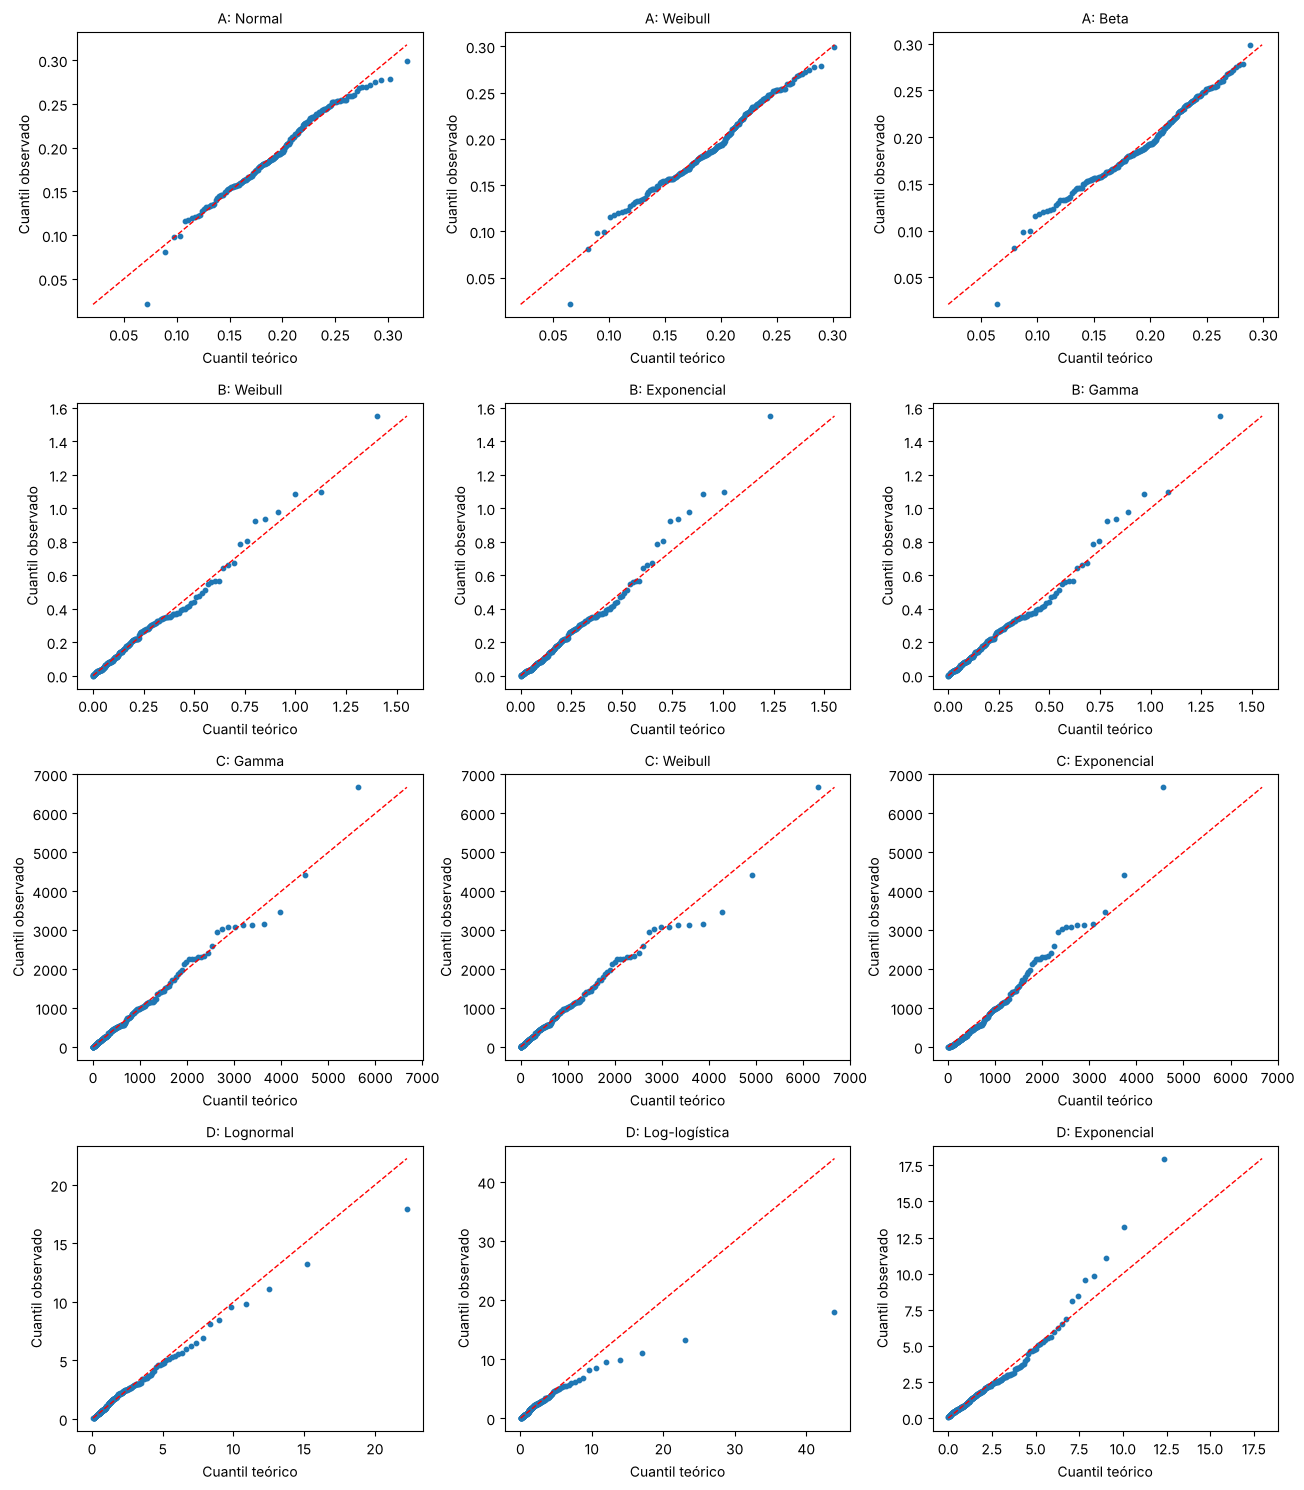

In [22]:
fig, axes = plt.subplots(4, 3, figsize=(13, 15))
for row, k in enumerate(NAMES):
    x = np.sort(data[k])
    _, modelos = resultados[k]
    p = (np.arange(1, len(x) + 1) - 0.5) / len(x)
    for col, nombre in enumerate(top3[k].index):
        dist, params = modelos[nombre]
        q = dist.ppf(p, *params)
        ax = axes[row, col]
        ax.scatter(q, x, s=10)
        lim = [min(q.min(), x.min()), max(q.max(), x.max())]
        ax.plot(lim, lim, 'r--', lw=1)
        ax.set_title(f'{k}: {nombre}', fontsize=10)
        ax.set_xlabel('Cuantil teórico'); ax.set_ylabel('Cuantil observado')
plt.tight_layout(); plt.show()

### ¿Cuál de las tres distribuciones con mejor ajuste seleccionaría por cada conjunto de datos? ¿Por qué?

**Dataset A → Normal** $\;N(\mu \approx 0.195,\ \sigma \approx 0.0437)$.
Tiene el menor AIC y BIC de las nueve y un SSE muy cercano al mínimo; Weibull (forma ≈ 5.1) y Beta quedan muy cerca, lo cual es esperable porque con esos parámetros también tienen forma de campana casi simétrica. Se elige la normal por ser la más simple (2 parámetros, fácil de interpretar) con el mejor criterio de información. La normal admite valores negativos, pero aquí $P(X<0)$ es ≈ $4\times10^{-6}$ (la media está a ~4.5 σ de cero), así que en la práctica no es un problema (se puede truncar en 0 al simular). **Advertencia:** A está correlacionado (5.2), así que esta normal describe solo la distribución marginal; generar valores IID de ella no reproduciría la dependencia observada.

**Dataset B → Exponencial** $\;\text{Exp}(\text{scale} = 1/\lambda \approx 0.205,\ \lambda \approx 4.87)$.
Weibull (forma ≈ 0.91) y Gamma (forma ≈ 0.86) tienen AIC marginalmente menor y menor SSE, pero sus parámetros de forma son cercanos a 1, que es justamente el caso en que ambas se reducen a la exponencial. La exponencial tiene el **menor BIC** (que penaliza más la complejidad), la diferencia de AIC es de apenas ≈1 punto (no significativa; diferencias < 2 se consideran equivalentes), y con un solo parámetro es la más parsimoniosa. Además es consistente con lo observado en 5.1 (CV ≈ 1) y 5.2 (proceso IID y estacionario, es decir, llegadas de Poisson). Si se quisiera capturar el ligero exceso de valores muy pequeños, la Weibull sería la alternativa.

**Dataset C → Weibull** $\;(\text{forma} \approx 0.80,\ \text{scale} \approx 676)$ (o Gamma, prácticamente empatada).
Weibull y Gamma empatan en el rango promedio (la gamma aparece primera en la tabla solo por el desempate por BIC, con una diferencia de 0.6 puntos). Se elige la Weibull porque tiene el SSE claramente menor (≈2.5e‑8 frente a ≈4.5e‑8) con AIC/BIC prácticamente iguales, y ambas superan con claridad a la exponencial (ΔAIC ≈ 16). Su forma < 1 refleja que hay más valores pequeños y una cola más larga que en una exponencial. **Sin embargo**, el análisis de 5.2 mostró que C **no es estacionario**: los tiempos entre llegadas crecen con el tiempo. Ninguna distribución univariada es adecuada para simular ese proceso; la forma < 1 de la Weibull es en realidad un artefacto de mezclar regímenes con medias muy distintas. La recomendación es modelar la tendencia (p. ej., proceso de Poisson no homogéneo con tasa decreciente, o ajustar distribuciones por tramos de tiempo) y usar esta Weibull solo como aproximación global.

**Dataset D → Lognormal** $\;(\sigma \approx 1.02,\ \text{scale} = e^{\mu} \approx 1.27 \Rightarrow \mu \approx 0.24)$.
Tiene el menor AIC y BIC; la log‑logística queda segunda (SSE algo menor, pero AIC/BIC ≈ 5.5 puntos peor) y la exponencial tercera (ΔAIC ≈ 15). La lognormal reproduce el pico del histograma cerca de 0.5 (la exponencial pone la moda en cero) y la cola pesada (valores de hasta ≈18, asimetría ≈ 3.2); en el gráfico Q‑Q, la exponencial subestima los valores grandes, mientras que la log‑logística tiende a sobreestimar la cola extrema. Al ser D un proceso IID y estacionario (5.2), la lognormal es adecuada para usarla directamente en la simulación.

### Resumen de la selección

In [23]:
seleccion = {'A': 'Normal', 'B': 'Exponencial', 'C': 'Weibull', 'D': 'Lognormal'}
supuestos = {'A': 'Estacionario, CORRELACIONADO (no IID)', 'B': 'IID, estacionario',
             'C': 'NO estacionario (tendencia creciente)', 'D': 'IID, estacionario'}
resumen = pd.DataFrame([{
    'Dataset': k,
    'Evaluación de supuestos (5.2)': supuestos[k],
    'Top 3 (5.3)': ', '.join(top3[k].index),
    'Distribución seleccionada': seleccion[k],
    'Parámetros': resultados[k][0].loc[seleccion[k], 'Parámetros'],
    'AIC': resultados[k][0].loc[seleccion[k], 'AIC'],
    'BIC': resultados[k][0].loc[seleccion[k], 'BIC'],
} for k in NAMES]).set_index('Dataset')
resumen

,Evaluación de supuestos (5.2),Top 3 (5.3),Distribución seleccionada,Parámetros,AIC,BIC
Dataset,,,,,,
A,"Estacionario, CORRELACIONADO (no IID)","Normal, Weibull, Beta",Normal,"loc=0.195, scale=0.0437",-680.587,-673.99
B,"IID, estacionario","Weibull, Exponencial, Gamma",Exponencial,"loc=0*, scale=0.2054",-231.131,-227.833
C,NO estacionario (tendencia creciente),"Gamma, Weibull, Exponencial",Weibull,"c=0.8007, loc=0*, scale=676","3,040.81","3,047.41"
D,"IID, estacionario","Lognormal, Log-logística, Exponencial",Lognormal,"s=1.019, loc=0*, scale=1.273",675.893,682.489


## Conclusiones

1. La estadística descriptiva y los histogramas permiten proponer familias candidatas (simétrica para A; sesgadas a la derecha para B, C y D), pero no detectan dependencia ni cambios en el tiempo.
2. Las gráficas de la sección 5.2 son imprescindibles antes de ajustar: **B y D** son consistentes con IID; **A** es estacionario pero autocorrelacionado ($\rho_1 \approx 0.5$) y **C** tiene una tendencia creciente (no estacionario). Para A y C, ajustar una sola distribución IID es una simplificación que debe advertirse en el modelo de simulación.
3. SSE, AIC y BIC no siempre coinciden: el SSE depende del número de clases del histograma y solo compara la forma, mientras que AIC/BIC usan todos los datos y penalizan los parámetros extra. Por ello, la selección final combina las tres métricas con criterios de **parsimonia** e **interpretación física** (p. ej., preferir la exponencial en B frente a Weibull/Gamma con forma ≈ 1).
4. Distribuciones seleccionadas: **A → Normal**, **B → Exponencial**, **C → Weibull** (con la salvedad de la no estacionariedad), **D → Lognormal**.

## Bibliografía

- [Banks98] Jerry Banks. *Handbook of Simulation: Principles, Methodology, Advances, Applications, and Practice.* John Wiley & Sons, 1998. Capítulo 3.
- [Amat2021] Joaquín Amat Rodrigo. *Ajuste y selección de distribuciones con Python.* https://www.cienciadedatos.net/documentos/pystats01-ajuste-distribuciones-python.html — https://doi.org/10.5281/zenodo.10006330
- Notebooks de clase: *Example. Input Data Analysis*, *Fitting data to a distribution*, *Distribution fitting with scipy*, *Fit data to distributions with SciPy*, *Fitting Niño data to a distribution*.
- SciPy `scipy.stats` documentation: https://docs.scipy.org/doc/scipy/reference/stats.html